# Analisi dei Segnali del Giroscopio

Analisi dei segnali del giroscopio da smartphone per il riconoscimento di attività umane.

**Dataset**: 10 utenti, frequenza di campionamento 50 Hz

## 1. Import Librerie

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import signal, fft

# Configurazione
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

# Parametri
SAMPLING_FREQ = 50  # Hz
RAWDATA_PATH = Path('RawData')

## 2. Caricamento Dati

I 3 utenti più distinti sono stati identificati tramite l'analisi esplorativa in `analisi_esplorativa_dataset.ipynb`. 

Qui procediamo con l'analisi approfondita usando questi utenti selezionati.

In [ ]:
# Carica il file delle etichette
labels = pd.read_csv(RAWDATA_PATH / 'labels.txt', sep=' ', header=None,
                     names=['exp_id', 'user_id', 'activity_id', 'start', 'end'])

# NOTA: I 3 utenti selezionati provengono dall'analisi esplorativa
# Qui carichiamo un file di esempio per iniziare l'analisi dettagliata
# (gli utenti selezionati verranno specificati dopo aver eseguito analisi_esplorativa_dataset.ipynb)

sample_file = RAWDATA_PATH / 'gyro_exp01_user01.txt'
gyro_data = pd.read_csv(sample_file, sep=' ', header=None, names=['x', 'y', 'z'])

print(f"File caricato: {sample_file.name}")
print(f"Numero di campioni: {len(gyro_data)}")
print(f"Durata segnale: {len(gyro_data) / SAMPLING_FREQ:.2f} secondi")
print(f"\nPrime 5 righe:")
gyro_data.head()

File caricato: gyro_exp01_user01.txt
Numero di campioni: 20598
Durata segnale: 411.96 secondi

Prime 5 righe:


,x,y,z
0,-0.054978,-0.069639,-0.030849
1,-0.012523,0.019242,-0.038485
2,-0.023518,0.276417,0.006414
3,-0.093462,0.367741,0.001222
4,-0.124311,0.476780,-0.022907


## 3. Definizione del Segnale e Base Temporale

I dati del giroscopio rappresentano velocità angolari sui tre assi (x, y, z) come sequenze a tempo discreto $x[n]$, dove $n$ è l'indice intero che rappresenta la progressione temporale dei campioni.

**Parametri fondamentali:**
- Periodo di campionamento: $T = 1/f_s = 1/50 = 0.02$ secondi
- Frequenza di campionamento: $f_s = 50$ Hz

Periodo di campionamento T = 0.0200 s
Numero di campioni N = 20598
Durata totale = 411.94 s


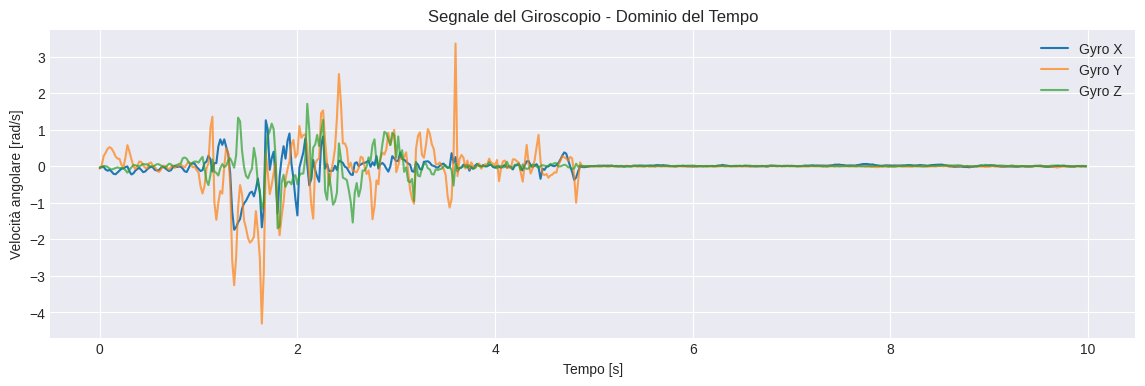

In [3]:
# Definizione della base temporale
N = len(gyro_data)  # Numero totale di campioni
T = 1 / SAMPLING_FREQ  # Periodo di campionamento (secondi)
n = np.arange(N)  # Indici discreti [0, 1, 2, ..., N-1]
t = n * T  # Scala temporale in secondi

print(f"Periodo di campionamento T = {T:.4f} s")
print(f"Numero di campioni N = {N}")
print(f"Durata totale = {t[-1]:.2f} s")

# Visualizzazione di un segmento del segnale
plt.figure(figsize=(14, 4))
segment = slice(0, 500)  # Primi 500 campioni (10 secondi)
plt.plot(t[segment], gyro_data['x'].values[segment], label='Gyro X')
plt.plot(t[segment], gyro_data['y'].values[segment], label='Gyro Y', alpha=0.7)
plt.plot(t[segment], gyro_data['z'].values[segment], label='Gyro Z', alpha=0.7)
plt.xlabel('Tempo [s]')
plt.ylabel('Velocità angolare [rad/s]')
plt.title('Segnale del Giroscopio - Dominio del Tempo')
plt.legend()
plt.grid(True)
plt.show()

## 4. Verifica del Campionamento e Anti-aliasing

**Criterio di Nyquist:** La frequenza di campionamento deve essere almeno il doppio della banda massima del segnale: $f_s \geq 2f_b$

- Frequenza di campionamento: $f_s = 50$ Hz
- Frequenza massima rappresentabile (Nyquist): $f_{Nyquist} = f_s/2 = 25$ Hz

Analizziamo lo spettro per verificare se ci sono componenti significative oltre i 25 Hz che potrebbero indicare aliasing.

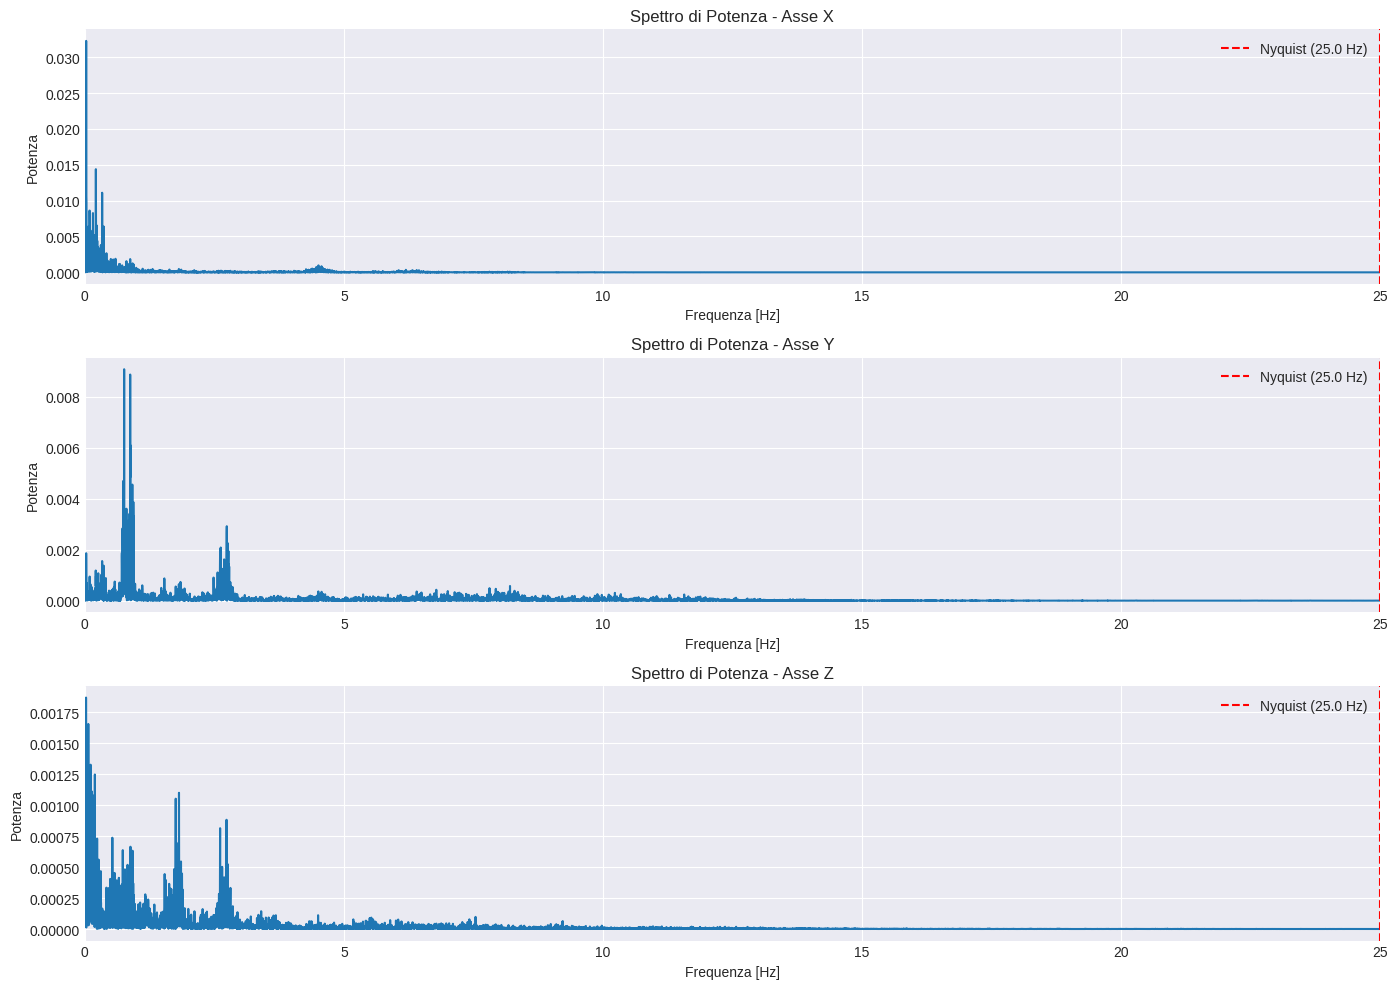

Frequenza di Nyquist: 25.0 Hz
Se la maggior parte dell'energia è concentrata sotto i 25 Hz, il criterio di Nyquist è rispettato.


In [4]:
# Calcolo della DFT (FFT) per verificare il contenuto spettrale
def compute_spectrum(signal_data, fs):
    """Calcola lo spettro di potenza del segnale"""
    N = len(signal_data)
    yf = np.fft.fft(signal_data)
    xf = np.fft.fftfreq(N, 1/fs)[:N//2]
    power = (2.0/N * np.abs(yf[:N//2]))**2
    return xf, power

# Analizza i tre assi
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
f_nyquist = SAMPLING_FREQ / 2

for i, (ax, axis) in enumerate(zip(axes, ['x', 'y', 'z'])):
    freqs, power = compute_spectrum(gyro_data[axis].values, SAMPLING_FREQ)
    ax.plot(freqs, power)
    ax.axvline(f_nyquist, color='r', linestyle='--', label=f'Nyquist ({f_nyquist} Hz)')
    ax.set_xlabel('Frequenza [Hz]')
    ax.set_ylabel('Potenza')
    ax.set_title(f'Spettro di Potenza - Asse {axis.upper()}')
    ax.set_xlim(0, SAMPLING_FREQ/2)
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

print(f"Frequenza di Nyquist: {f_nyquist} Hz")
print("Se la maggior parte dell'energia è concentrata sotto i 25 Hz, il criterio di Nyquist è rispettato.")

## 5. Classificazione del Segnale (Energia vs Potenza)

Un segnale può essere classificato come:
- **Segnale di Energia:** durata finita con energia totale $E_x = \sum_{n} |x[n]|^2 < \infty$
- **Segnale di Potenza:** durata molto lunga o infinita, si considera la potenza media $\bar{P}_x = \lim_{N \to \infty} \frac{1}{N} \sum_{n=0}^{N-1} |x[n]|^2$

I nostri dati hanno durata finita, ma essendo misure continue nel tempo possiamo calcolare entrambe le grandezze.

In [5]:
# Calcolo energia e potenza per ciascun asse
results = {}

for axis in ['x', 'y', 'z']:
    signal = gyro_data[axis].values
    
    # Energia totale: somma dei quadrati
    energy = np.sum(signal**2)
    
    # Potenza media: energia diviso numero di campioni
    power = energy / len(signal)
    
    # Valore RMS (Root Mean Square)
    rms = np.sqrt(power)
    
    results[axis] = {
        'Energia totale': energy,
        'Potenza media': power,
        'RMS': rms
    }

# Visualizza risultati
results_df = pd.DataFrame(results).T
print("Caratterizzazione Energetica del Segnale:")
print(results_df)

print(f"\nInterpretazione:")
print(f"- Il segnale ha durata finita ({len(gyro_data)} campioni, {len(gyro_data)/SAMPLING_FREQ:.2f}s)")
print(f"- Possiamo classificarlo come SEGNALE DI ENERGIA")
print(f"- La potenza media è utile per confrontare l'intensità del segnale tra gli assi")

Caratterizzazione Energetica del Segnale:
   Energia totale  Potenza media       RMS
x     6591.496847       0.320007  0.565691
y     6121.597642       0.297194  0.545155
z     2026.290708       0.098373  0.313645

Interpretazione:
- Il segnale ha durata finita (20598 campioni, 411.96s)
- Possiamo classificarlo come SEGNALE DI ENERGIA
- La potenza media è utile per confrontare l'intensità del segnale tra gli assi


## 6. Inquadramento Statistico (Segnali Aleatori)

I dati del giroscopio includono intrinsecamente rumore e devono essere trattati come **segnali aleatori**.

Verificheremo:
1. **Valore atteso (media):** $\hat{m}_N = \frac{1}{N} \sum_{n=0}^{N-1} x[n]$ - identifica bias/offset del sensore
2. **Varianza:** $\sigma^2 = \frac{1}{N} \sum_{n=0}^{N-1} (x[n] - \hat{m}_N)^2$ - quantifica la potenza del rumore
3. **Stazionarietà (WSS):** Un segnale è Wide-Sense Stationary se media costante e autocorrelazione dipende solo dal lag

In [ ]:
# Analisi statistica per ciascun asse
stats_results = {}

for axis in ['x', 'y', 'z']:
    signal = gyro_data[axis].values
    
    # Media (valore atteso)
    mean = np.mean(signal)
    
    # Varianza
    variance = np.var(signal)
    
    # Deviazione standard
    std = np.sqrt(variance)
    
    stats_results[axis] = {
        'Media (μ)': mean,
        'Varianza (σ²)': variance,
        'Std Dev (σ)': std,
        'Min': np.min(signal),
        'Max': np.max(signal)
    }

# Visualizza statistiche
stats_df = pd.DataFrame(stats_results).T
print("Statistiche dei Segnali Aleatori:")
print(stats_df)

# Visualizza distribuzione dei valori
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, axis in enumerate(['x', 'y', 'z']):
    axes[i].hist(gyro_data[axis], bins=50, edgecolor='black', alpha=0.7)
    axes[i].axvline(stats_results[axis]['Media (μ)'], color='r', 
                    linestyle='--', label=f"μ={stats_results[axis]['Media (μ)']:.4f}")
    axes[i].set_title(f'Distribuzione Asse {axis.upper()}')
    axes[i].set_xlabel('Velocità angolare [rad/s]')
    axes[i].set_ylabel('Frequenza')
    axes[i].legend()
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 6.1 Verifica della Stazionarietà (WSS)

Per verificare se il segnale è Wide-Sense Stationary, analizziamo:
1. Se la media è costante nel tempo
2. Se l'autocorrelazione dipende solo dal lag (differenza temporale)

In [ ]:
# Verifica stazionarietà: dividiamo il segnale in segmenti e calcoliamo la media
def check_stationarity(signal, n_segments=5):
    """Verifica se la media è costante dividendo il segnale in segmenti"""
    segment_size = len(signal) // n_segments
    means = []
    
    for i in range(n_segments):
        start = i * segment_size
        end = start + segment_size
        segment = signal[start:end]
        means.append(np.mean(segment))
    
    return means

# Analizza asse X come esempio
signal_x = gyro_data['x'].values
segment_means = check_stationarity(signal_x, n_segments=10)

plt.figure(figsize=(14, 4))
plt.plot(segment_means, 'o-', linewidth=2, markersize=8)
plt.axhline(np.mean(signal_x), color='r', linestyle='--', 
            label=f'Media globale: {np.mean(signal_x):.4f}')
plt.xlabel('Segmento')
plt.ylabel('Media del segmento')
plt.title('Verifica Stazionarietà - Media per Segmenti (Asse X)')
plt.grid(True)
plt.legend()
plt.show()

print(f"Media globale: {np.mean(signal_x):.6f}")
print(f"Std dev delle medie dei segmenti: {np.std(segment_means):.6f}")
print(f"\nSe la std dev è piccola rispetto alla media, il segnale è approssimativamente stazionario.")

### 6.2 Autocorrelazione

L'autocorrelazione misura la somiglianza del segnale con una sua versione ritardata (lag). Per un segnale WSS, dipende solo dal lag e non dal tempo assoluto.

In [ ]:
# Calcolo dell'autocorrelazione
from scipy.signal import correlate

def compute_autocorrelation(signal):
    """Calcola l'autocorrelazione normalizzata"""
    # Rimuovi la media
    signal_centered = signal - np.mean(signal)
    
    # Calcola autocorrelazione
    autocorr = correlate(signal_centered, signal_centered, mode='full')
    autocorr = autocorr[len(autocorr)//2:]  # Prendi solo lag positivi
    
    # Normalizza
    autocorr = autocorr / autocorr[0]
    
    return autocorr

# Calcola autocorrelazione per asse X
autocorr_x = compute_autocorrelation(signal_x)
lags = np.arange(len(autocorr_x)) / SAMPLING_FREQ

# Visualizza solo i primi 100 campioni (2 secondi)
max_lag = 100
plt.figure(figsize=(14, 5))
plt.plot(lags[:max_lag], autocorr_x[:max_lag], linewidth=2)
plt.xlabel('Lag [s]')
plt.ylabel('Autocorrelazione normalizzata')
plt.title('Funzione di Autocorrelazione - Asse X')
plt.grid(True)
plt.axhline(0, color='k', linestyle='--', alpha=0.3)
plt.show()

print("L'autocorrelazione mostra come il segnale si correla con se stesso a diversi ritardi temporali.")
print("Un rapido decadimento indica bassa correlazione temporale (segnale meno predicibile).")

## 7. Operazioni Preliminari di Manipolazione

In questa sezione esploriamo operazioni fondamentali per allineare e preparare i dati:
- **Shift (spostamento):** sincronizzazione tra assi
- **Flip (rovesciamento):** inversione dell'orientamento
- **Decimazione/Espansione:** cambio della frequenza di campionamento

In [ ]:
# Esempio di operazioni di manipolazione

# 1. SHIFT: Sposta il segnale di k campioni
def shift_signal(signal, k):
    """Sposta il segnale di k campioni (k>0 ritardo, k<0 anticipo)"""
    if k > 0:
        return np.concatenate([np.zeros(k), signal[:-k]])
    elif k < 0:
        return np.concatenate([signal[-k:], np.zeros(-k)])
    return signal

# 2. FLIP: Rovescia il segnale
def flip_signal(signal):
    """Rovescia il segnale nel tempo"""
    return signal[::-1]

# 3. DECIMAZIONE: Riduce la frequenza di campionamento
def decimate_signal(signal, factor):
    """Decima il segnale (prende 1 campione ogni 'factor')"""
    return signal[::factor]

# Esempio pratico: confronto segnale originale vs operazioni
segment = slice(1000, 1200)  # Segmento di 200 campioni
original = signal_x[segment]

fig, axes = plt.subplots(4, 1, figsize=(14, 10))

# Originale
axes[0].plot(original)
axes[0].set_title('Segnale Originale')
axes[0].set_ylabel('Ampiezza')
axes[0].grid(True)

# Shift di 10 campioni
shifted = shift_signal(original, 10)
axes[1].plot(original, alpha=0.5, label='Originale')
axes[1].plot(shifted, label='Shifted (+10 campioni)')
axes[1].set_title('Shift (Ritardo)')
axes[1].set_ylabel('Ampiezza')
axes[1].legend()
axes[1].grid(True)

# Flip
flipped = flip_signal(original)
axes[2].plot(original, alpha=0.5, label='Originale')
axes[2].plot(flipped, label='Flipped')
axes[2].set_title('Flip (Rovesciamento)')
axes[2].set_ylabel('Ampiezza')
axes[2].legend()
axes[2].grid(True)

# Decimazione (fattore 2)
decimated = decimate_signal(original, 2)
axes[3].plot(original, alpha=0.5, label='Originale (50 Hz)')
axes[3].plot(np.arange(0, len(original), 2), decimated, 'o-', label='Decimato (25 Hz)')
axes[3].set_title('Decimazione (fattore 2)')
axes[3].set_ylabel('Ampiezza')
axes[3].set_xlabel('Campioni')
axes[3].legend()
axes[3].grid(True)

plt.tight_layout()
plt.show()

print("Operazioni implementate:")
print("1. Shift: utile per sincronizzare segnali con ritardi temporali")
print("2. Flip: inversione temporale del segnale")
print("3. Decimazione: riduzione della frequenza di campionamento")

## 8. Riepilogo dell'Analisi Preliminare

Abbiamo completato la fase di inquadramento e pre-elaborazione dei dati:

✅ **Definizione del segnale:** Identificati come sequenze discrete x[n] a 50 Hz  
✅ **Verifica Nyquist:** Campionamento adeguato (f_Nyquist = 25 Hz)  
✅ **Classificazione:** Segnali di energia con durata finita  
✅ **Analisi statistica:** Caratterizzazione di media, varianza e distribuzione  
✅ **Stazionarietà:** Verifica delle proprietà WSS  
✅ **Operazioni di base:** Shift, flip, decimazione implementati

**Prossimi passi:**
- Filtraggio e rimozione del rumore
- Analisi spettrale avanzata
- Estrazione di features per classificazione attività
- Confronto tra diverse attività e utenti